In [ ]:
print("Лабораторная работа №2")
print("Вариант 9 - Регрессия и классификация")

Лабораторная работа №2
Вариант 9 - Регрессия и классификация


In [15]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.metrics import r2_score, mean_absolute_error, accuracy_score, precision_score, recall_score, ConfusionMatrixDisplay
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from imblearn.over_sampling import SMOTE

print("Библиотеки подключены.")

Библиотеки подключены.


In [ ]:
df_twitter = pd.read_csv(
    "/content/In-Depth Twitter Retweet Analysis Dataset.csv"
)

print(df_twitter.columns.tolist())
print("Размер датасета:", df_twitter.shape)

['Unnamed: 0', 'weekday', 'hour', 'day', 'lang', 'reach', 'retweetcount', 'likes', 'klout', 'sentiment', 'locationid', 'isreshare']
Размер датасета: (5000, 12)


In [ ]:
data = df_twitter[["reach", "retweetcount"]].dropna()

X = data[["reach"]]
y = data["retweetcount"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

model = LinearRegression()
model.fit(X_train, y_train)

y_pred = model.predict(X_test)

print("R²:", round(r2_score(y_test, y_pred), 3))
print("MAE:", round(mean_absolute_error(y_test, y_pred), 3))

R²: -0.081
MAE: 9.581


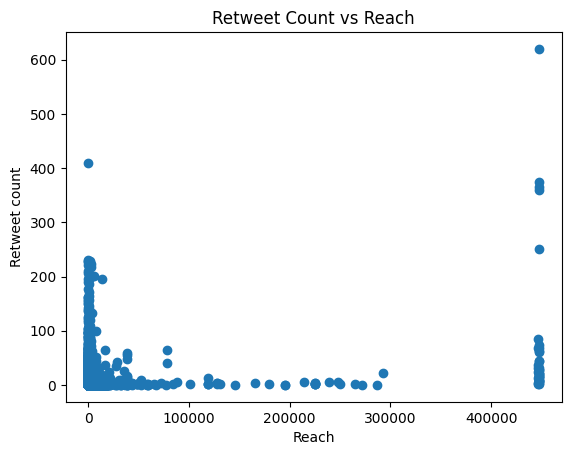

In [ ]:
plt.scatter(df_twitter["reach"], df_twitter["retweetcount"])
plt.xlabel("Reach")
plt.ylabel("Retweet count")
plt.title("Retweet Count vs Reach")
plt.show()

In [8]:
df_credit = pd.read_csv("/content/creditcard.csv")

print("Размер датасета:", df_credit.shape)
print(df_credit["Class"].value_counts())

Размер датасета: (284807, 31)
Class
0    284315
1       492
Name: count, dtype: int64


In [9]:
!pip install imbalanced-learn

In [18]:
# Удаляем строки без целевого класса
df_credit = df_credit.dropna(subset=["Class"])

X = df_credit.drop(columns=["Class"])
y = df_credit["Class"].astype(int)

# Масштабируем признаки
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# Балансируем данные с помощью SMOTE
smote = SMOTE(random_state=42)
X_balanced, y_balanced = smote.fit_resample(X_scaled, y)

print("Количество классов после SMOTE:")
print(pd.Series(y_balanced).value_counts())

# Разделяем сбалансированные данные на обучающую и тестовую выборки
X_train, X_test, y_train, y_test = train_test_split(
    X_balanced, y_balanced,
    test_size=0.2,
    random_state=42,
    stratify=y_balanced
)

# Обучаем логистическую регрессию
model_credit = LogisticRegression(max_iter=1000)
model_credit.fit(X_train, y_train)

# Делаем предсказания
y_pred = model_credit.predict(X_test)

# Оцениваем модель
print("Accuracy:", round(accuracy_score(y_test, y_pred), 4))
print("Precision:", round(precision_score(y_test, y_pred, zero_division=0), 4))
print("Recall:", round(recall_score(y_test, y_pred, zero_division=0), 4))

Количество классов после SMOTE:
Class
0    284315
1    284315
Name: count, dtype: int64
Accuracy: 0.9492
Precision: 0.9735
Recall: 0.9235


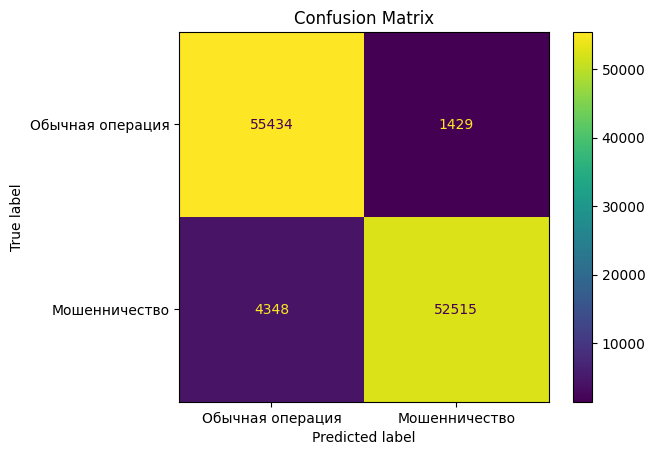

In [19]:
ConfusionMatrixDisplay.from_predictions(
    y_test, y_pred,
    display_labels=["Обычная операция", "Мошенничество"],
    values_format="d"
)
plt.title("Confusion Matrix")
plt.show()